# Micrograd from scratch

Learning project on backpropagation by implementing it from scratch. This is a follow-along implementation of Andrej Karpathy's lecture on neural networks ([Link](https://www.youtube.com/watch?v=VMj-3S1tku0))

## What's being implemented?
- A tiny scalar auto gradient engine
- Small neural network trained using it

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

## Functions and derivatives


In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

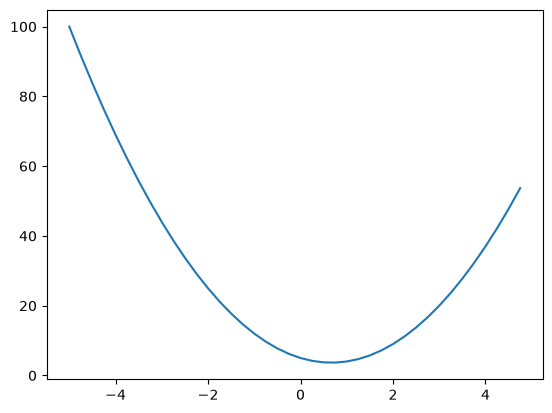

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [5]:
h = 0.00000001
x = -2.0
(f(x + h) - f(x))/h

-15.999999902760464

### Derivatives across multiple variables


In [6]:
a = 2.0
b = -3.0
c = 10.0

In [7]:
h = 0.0001

d1 = a*b + c

c += h
d2 = a*b + c

print("d1", d1)
print("d2", d2)
print("slope", (d2 - d1)/h)

d1 4.0
d2 4.0001
slope 0.9999999999976694


## Components of micrograd


In [8]:
class Value:

    def __init__(self, data, _children=()):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._backward = lambda : None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        
        out = Value(self.data + other.data, (self, other))

        def _backward():
            self.grad  += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        
        out = Value(self.data * other.data, (self,other))

        def _backward():
            self.grad  += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out

    def __rmul__(self, other):
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self,))

        def _backward():
            self.grad += out.grad * other * (self.data**(other - 1))
        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * other**-1

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,))

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1)/ (math.exp(2 * x) + 1)
        out = Value(t, (self,))

        def _backward():
            self.grad += out.grad * (1 - t**2)
        out._backward = _backward

        return out

    def zero_grad(self):
        self.grad = 0.0

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        

In [9]:
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)

In [10]:
d = a*b + c

In [11]:
# Skipping part of graph viz and deriving the logic/intuition for back propagation algorithm
# Skipping part on tanh as activation and computing the gradients of an expression using tanh
# Skipping section on pytorch

In [12]:
d.backward()

In [13]:
print('grad(d)', d.grad)
print('grad(c)', c.grad)
print('grad(b)', b.grad)
print('grad(a)', a.grad)

grad(d) 1.0
grad(c) 1.0
grad(b) 2.0
grad(a) -3.0


In [14]:
a = Value(2.0)
b = Value(5.0)
e = a / b  
e.backward()

print('e', e.data)
print('grad(e)', e.grad)
print('grad(b)', b.grad)
print('grad(a)', a.grad)

e 0.4
grad(e) 1.0
grad(b) -0.08
grad(a) 0.2


## Building Neural Nets


In [15]:
class Neuron:

    def __init__(self, nin, learning_rate):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))
        self._learning_rate = learning_rate

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()

        return out

    def _parameters(self):
        return self.w +  [self.b]

    def zero_grad(self):
        params = self._parameters()
        for p in params:
            p.zero_grad()

    def update(self):
        params = self._parameters()

        for p in params:
            p.data += -1 * self._learning_rate * p.grad


class Layer:
    def __init__(self, nin, nout, learning_rate):
        self.neurons = [Neuron(nin, learning_rate) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def zero_grad(self):
        for neuron in self.neurons:
            neuron.zero_grad()

    def update(self):
        for neuron in self.neurons:
            neuron.update()

class MLP:
    def __init__(self, nin, nouts, learning_rate):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1], learning_rate) for i in range(len(nouts))]

    def __call__(self, x):
        out = x
        for layer in self.layers:
            out = layer(out)

        return out

    def zero_grad(self):
        for layer in self.layers:
            layer.zero_grad()

    def update(self):
        for layer in self.layers:
            layer.update()

In [16]:
x = [2.0, 3.0]
n = Neuron(2, 0.01)
n(x)

Value(data=0.9996587836303463)

In [17]:
mlp = MLP(3, [4, 5, 1], 0.01)

In [18]:
x = [2.0, -1.0, 3.14]
mlp(x)

Value(data=-0.9947306497795979)

# Testing our neural net

In [19]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]

In [20]:
ypred = [mlp(x) for x in xs]
ypred

[Value(data=0.573651833369767),
 Value(data=-0.9743027955340705),
 Value(data=-0.9204403769338239),
 Value(data=-0.898580788080041)]

## Loss - capturing performance of neural net predictions

In [21]:
loss = sum((- ygt + yout)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=3.793371847995387)

In [22]:
mlp.zero_grad()

mlp.layers[0].neurons[0].w[0].grad

0.0

In [23]:
loss.backward()

mlp.layers[0].neurons[0].w[0].grad

-1.7160655965181666

## Running gradient descent

In [24]:
mlp.layers[0].neurons[0].w[0].data, mlp.layers[0].neurons[0].w[0].grad

(0.08580598425061114, -1.7160655965181666)

In [25]:
mlp.update()

In [26]:
mlp.layers[0].neurons[0].w[0].data, mlp.layers[0].neurons[0].w[0].grad

(0.10296664021579281, -1.7160655965181666)

### putting it altogether
    

In [27]:
mlp = MLP(3, [4, 5, 1], 0.05)

In [28]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [-1.0, 1.0, 1.0, -1.0]

In [29]:
for k in range(50):
    ypred = [mlp(x) for x in xs]

    loss = sum((- ygt + yout)**2 for ygt, yout in zip(ys, ypred))

    mlp.zero_grad()
    loss.backward()

    mlp.update()

    print(k, loss)

0 Value(data=4.4834527112931735)
1 Value(data=1.5418047987415155)
2 Value(data=0.6960912283159679)
3 Value(data=0.43562582902426594)
4 Value(data=0.31047329445867783)
5 Value(data=0.23805978825672017)
6 Value(data=0.19139675944427356)
7 Value(data=0.15908089662828057)
8 Value(data=0.13551227562882798)
9 Value(data=0.1176392125492117)
10 Value(data=0.10366574615855019)
11 Value(data=0.09247030487402859)
12 Value(data=0.08331856755348979)
13 Value(data=0.07571084285820752)
14 Value(data=0.06929600383403131)
15 Value(data=0.0638205256817392)
16 Value(data=0.059097045453681246)
17 Value(data=0.054984274742149626)
18 Value(data=0.051373772147006155)
19 Value(data=0.048181000224597224)
20 Value(data=0.045339137148696945)
21 Value(data=0.042794705423932274)
22 Value(data=0.04050442675023556)
23 Value(data=0.03843292133479071)
24 Value(data=0.03655099955055451)
25 Value(data=0.034834376070205494)
26 Value(data=0.033262689914244095)
27 Value(data=0.031818749096599666)
28 Value(data=0.0304879422

In [30]:
ypred

[Value(data=-0.9270260999612467),
 Value(data=0.9293584212229561),
 Value(data=0.9482207920077845),
 Value(data=-0.946307406145492)]

# Py Torch demo

In [31]:
import torch

In [33]:
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True

w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True

b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True

n = x1 * w1 + x2 * w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('----')
print('x2', x2.grad.item())
print('x1', x1.grad.item())
print('w2', w2.grad.item())
print('w1', w1.grad.item())
print('b', b.grad.item())

0.7071066904050358
----
x2 0.5000001283844369
x1 -1.5000003851533106
w2 0.0
w1 1.0000002567688737
b 0.5000001283844369


NameError: name 'double' is not defined